# Лабораторная работа №15. Оценка и оптимизация полного CV-конвейера

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №15».

**Задача курса, взятая для конвейера:** сегментация объекта из лабораторной 10 (кластеризация k-means по цветности). **Данные:** `data/seg_scene.png` и `data/seg_mask.png` — та же полусинтетическая сцена с точной маской; из неё делается 10 вариантов с разным шумом и освещением, чтобы качество оценивалось не по одному кадру.

**Что зависит от компьютера.** Все времена в миллисекундах и FPS относятся к машине, на которой выполнялся ноутбук (её параметры печатаются в первой ячейке). При повторном запуске числа изменятся; отношения между вариантами (ускорение, порядок на графике) должны сохраниться.

## 1. О чём эта работа

### Знакомый пример

Вы выбираете маршрут в навигаторе. Один — самый короткий, но через центр с пробками. Другой — длиннее, зато по трассе. Третий — и длиннее второго, и медленнее. Третий можно сразу отбросить: он хуже второго по всем статьям. А между первым и вторым однозначного «лучше» нет — зависит от того, что вам важнее. И ещё: навигатор обещает «в среднем 30 минут», но раз в неделю дорога занимает час. Если вы едете в аэропорт, среднее вас не интересует — интересует, сколько бывает в плохой день.

### Основная идея

Алгоритм компьютерного зрения в реальной системе оценивают двумя числами сразу: **насколько хорошо** он решает задачу и **насколько быстро**. Ускорение почти всегда стоит качества. Эта работа — о том, как измерять скорость честно (время — случайная величина, и одного замера мало) и как сравнивать варианты, когда критериев два.

### Понятия

- **Конвейер (pipeline)** — вся цепочка от входной картинки до ответа: предобработка, алгоритм, постобработка.
- **Latency** — время обработки одного входа. **Throughput / FPS** — сколько входов обрабатывается за секунду.
- **Warm-up** — «прогрев»: первые запуски медленнее остальных (загрузка библиотек, заполнение кэшей процессора, выделение памяти). Их не включают в статистику.
- **Среднее** чувствительно к выбросам; **медиана** — значение, меньше которого половина замеров, — нет.
- **Перцентиль p95** — значение, меньше которого 95 % замеров. Описывает «плохой день»: каждый двадцатый запуск медленнее.
- **Стандартная ошибка среднего** $s/\sqrt n$ — насколько само среднее «гуляет» от серии к серии. В $\sqrt n$ раз меньше разброса отдельных замеров.
- **Доверительный интервал (CI) 95 %** — диапазон, который при повторении эксперимента накрывал бы истинное среднее в 95 % случаев.
- **Speedup** — во сколько раз вариант быстрее базового.
- **Доминирование.** Вариант A доминирует B, если A не хуже B по всем критериям и строго лучше хотя бы по одному. **Pareto frontier** (граница Парето) — множество вариантов, которых никто не доминирует: улучшить один критерий, оставаясь на границе, можно только ценой другого.

### Формулы

$$\mathrm{FPS}=\frac NT,\qquad \text{mean}=\frac1N\sum t_i,\qquad \text{p95}=\text{percentile}_{95}(t)$$

$N$ — число обработанных кадров, $T$ — суммарное время, $t_i$ — время $i$-го запуска.

$$\mathrm{CI}_{95}\approx\text{mean}\pm1.96\cdot\frac{s}{\sqrt n},\qquad \text{speedup}=\frac{T_{base}}{T_{opt}}$$

$s$ — стандартное отклонение замеров, $n$ — их число. Множитель 1.96 — из нормального распределения: в пределах 1.96 стандартных ошибок от центра лежит 95 % его массы.

In [1]:
import platform, sys, time, tracemalloc
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80})

SEED = 0
N_WARMUP, N_TIMINGS = 20, 100
N_SAMPLES = 10              # вариантов входного кадра
KMEANS_ITERS = 8            # фиксированное число итераций: одинаковая работа при каждом запуске
SCENE, MASK = "data/seg_scene.png", "data/seg_mask.png"

print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| OpenCV", cv2.__version__)
print("ОС:", platform.platform())
print("CPU:", platform.processor() or platform.machine(), "| логических ядер:", __import__("os").cpu_count(), "| потоков OpenCV:", cv2.getNumThreads())
print("устройство: CPU; batch = 1; входной кадр 640×480×3 uint8; seed =", SEED)

Python 3.12.14 | NumPy 2.5.3 | OpenCV 5.0.0
ОС: Windows-11-10.0.26200-SP0
CPU: Intel64 Family 6 Model 167 Stepping 1, GenuineIntel | логических ядер: 16 | потоков OpenCV: 16
устройство: CPU; batch = 1; входной кадр 640×480×3 uint8; seed = 0


## 2. Вопрос 1 — среднее и медиана

> Для timings [20,21,19,20,50] ms найдите mean и median. Объясните различие.

**Среднее:** $(20+21+19+20+50)/5=130/5=26$ ms.

**Медиана:** сортируем — $[19,20,20,21,50]$; посередине (третье из пяти) стоит **20** ms.

**Различие.** Четыре замера из пяти лежат в диапазоне 19–21 ms. Пятый, 50 ms, — выброс (сборка мусора, переключение на другой процесс). Среднее складывает все значения, и один выброс утянул его на 6 ms — до 26 ms, хотя ни один запуск столько не длился. Медиане важен только порядок: останется ли выброс 50 ms или станет 5000 ms, она не изменится.

Какое число правильное? Оба, но отвечают на разные вопросы. Медиана: «сколько обычно занимает один запуск» — 20 ms. Среднее: «сколько времени уйдёт на много запусков» — если обрабатывать 1000 кадров, уйдёт 26 секунд, а не 20, потому что выбросы тоже тратят время. Поэтому FPS считают по среднему.

In [2]:
t = np.array([20.0, 21, 19, 20, 50])
print("mean =", t.mean(), "ms; median =", np.median(t), "ms; отсортировано:", np.sort(t))
print("без выброса: mean =", t[:4].mean(), "ms")
print("FPS по среднему:", round(1000 / t.mean(), 2), " по медиане:", round(1000 / np.median(t), 2), "— второе завышает реальную пропускную способность")
t2 = t.copy(); t2[-1] = 5000
print("если выброс 5000 ms: mean =", t2.mean(), " median =", np.median(t2))

mean = 26.0 ms; median = 20.0 ms; отсортировано: [19. 20. 20. 21. 50.]
без выброса: mean = 20.0 ms
FPS по среднему: 38.46  по медиане: 50.0 — второе завышает реальную пропускную способность
если выброс 5000 ms: mean = 1016.0  median = 20.0


**Итог вопроса 1:** mean = 26 ms, median = 20 ms.

## 3. Вопрос 2 — доверительный интервал и граница Парето

> При n=100, mean=25 ms, s=5 ms найдите 95% CI. Для A(.92,15), B(.90,30), C(.88,55), D(.86,40), E(.82,80) по (F1,FPS) найдите dominated вариант и Pareto frontier.

### Доверительный интервал

**Стандартная ошибка:** $SE=s/\sqrt n=5/\sqrt{100}=0.5$ ms.

**Полуширина:** $1.96\cdot0.5=0.98$ ms.

**Интервал:** $25\pm0.98=[24.02,\ 25.98]$ ms.

**Смысл.** Отдельные запуски разбросаны на ±5 ms, но среднее по 100 запускам известно гораздо точнее — с точностью около ±1 ms. Это интервал для **среднего**, а не для отдельного запуска: он не говорит, что 95 % запусков уложатся в 24–26 ms (они уложатся примерно в $25\pm10$). Чтобы сузить интервал вдвое, нужно вчетверо больше замеров: ширина убывает как $1/\sqrt n$.

### Доминирование

Оба критерия — «чем больше, тем лучше». Вариант доминируется, если существует другой, у которого и F1, и FPS не меньше (и хотя бы одно строго больше).

Отсортируем по убыванию F1:

| вариант | F1 | FPS | есть ли вариант с бóльшим F1 **и** бóльшим FPS? |
|---|---|---|---|
| A | 0.92 | 15 | нет — у A наибольший F1 |
| B | 0.90 | 30 | выше по F1 только A, но у него FPS 15 < 30 — нет |
| C | 0.88 | 55 | A и B выше по F1, но оба медленнее — нет |
| D | 0.86 | 40 | **да: C** (0.88 > 0.86 и 55 > 40) |
| E | 0.82 | 80 | все выше по F1, но все медленнее — нет |

**D доминируется вариантом C**: C одновременно точнее и быстрее, выбирать D незачем ни при каких приоритетах.

**Граница Парето: A, B, C, E.** Вдоль неё рост FPS (15 → 30 → 55 → 80) сопровождается падением F1 (0.92 → 0.90 → 0.88 → 0.82). Выбор точки на границе — инженерное решение: нужен ли реальный масштаб времени (≥ 30 FPS — тогда B, C или E) или максимальное качество (A).

In [3]:
n, mean, s = 100, 25.0, 5.0
se = s / np.sqrt(n)
print(f"SE = {se}, margin = {1.96 * se:.2f}, CI = [{mean - 1.96 * se:.2f}, {mean + 1.96 * se:.2f}] ms")
print("ширина CI при других n:", {k: round(2 * 1.96 * s / np.sqrt(k), 2) for k in (5, 25, 100, 400)})

def pareto(points):
    """points: {имя: (quality, speed)}, оба «больше — лучше». Возвращает границу и {доминируемый: кем}."""
    front, dominated = [], {}
    for a, (qa, sa) in points.items():
        by = [b for b, (qb, sb) in points.items() if b != a and qb >= qa and sb >= sa and (qb > qa or sb > sa)]
        if by: dominated[a] = by
        else: front.append(a)
    return front, dominated

q2 = {"A": (0.92, 15), "B": (0.90, 30), "C": (0.88, 55), "D": (0.86, 40), "E": (0.82, 80)}
front, dom = pareto(q2)
print("Pareto frontier:", front, " dominated:", dom)

SE = 0.5, margin = 0.98, CI = [24.02, 25.98] ms
ширина CI при других n: {5: np.float64(8.77), 25: np.float64(3.92), 100: np.float64(1.96), 400: np.float64(0.98)}
Pareto frontier: ['A', 'B', 'C', 'E']  dominated: {'D': ['C']}


**Итог вопроса 2:** 95 % CI = [24.02, 25.98] ms; D доминируется C; граница Парето — A, B, C, E.

## 4. Задание 3 — код и эксперимент

### Шаги 1–2. Задача, метрика, условия

- **Задача:** бинарная сегментация объекта (лабораторная 10).
- **Основная метрика качества:** IoU с эталонной маской; дополнительно F1 (он же Dice).
- **Условия:** зафиксированы в первой ячейке — версии библиотек, процессор, число потоков, размер входа, batch = 1, seed.
- **Набор данных:** 10 вариантов одной сцены с разным шумом и разной силой неравномерного освещения. Маска у всех одна. Одни и те же 10 кадров используются для всех вариантов конвейера.

In [4]:
scene0 = cv2.imread(SCENE); gt = cv2.imread(MASK, cv2.IMREAD_GRAYSCALE) > 0
rng = np.random.default_rng(SEED)
H, W = gt.shape
samples = []
for _ in range(N_SAMPLES):
    ramp = np.linspace(rng.uniform(0.8, 1.0), rng.uniform(1.0, 1.2), W, dtype=np.float32)[None, :, None]
    x = scene0.astype(np.float32) * ramp + rng.normal(0, rng.uniform(2, 10), scene0.shape)
    samples.append(np.clip(x, 0, 255).astype(np.uint8))
print("кадров:", len(samples), samples[0].shape, samples[0].dtype, "| доля объекта в GT:", round(gt.mean(), 4))

кадров: 10 (480, 640, 3) uint8 | доля объекта в GT: 0.1859


### Шаг 3. Базовый конвейер

Пять шагов: уменьшение кадра (в базовом варианте — без уменьшения) → перевод в Lab → k-means по цветности $(a,b)$ на два кластера → морфологическое открытие 3×3 (убирает одиночные ложные пиксели, лабораторная 4) → возврат маски к исходному размеру.

K-means — собственная реализация из лабораторной 10, с двумя изменениями ради воспроизводимости замеров: начальные центры детерминированы (5-й и 95-й перцентили канала $a$), а число итераций фиксировано — чтобы каждый запуск выполнял одинаковый объём работы.

In [5]:
KERNEL = np.ones((3, 3), np.uint8)

def kmeans_ab(ab, iters=KMEANS_ITERS):
    """k-means, k=2, по пикселям (a, b); возвращает метки и центры."""
    a = ab[:, 0]
    lo, hi = np.percentile(a, [5, 95])
    centers = np.array([[lo, ab[:, 1].mean()], [hi, ab[:, 1].mean()]], dtype=np.float32)
    for _ in range(iters):
        d0 = ((ab - centers[0]) ** 2).sum(axis=1); d1 = ((ab - centers[1]) ** 2).sum(axis=1)
        labels = d1 < d0
        if labels.any() and (~labels).any():
            centers = np.stack([ab[~labels].mean(axis=0), ab[labels].mean(axis=0)])
    return labels, centers

def pipeline_kmeans(img, scale=1.0):
    small = img if scale == 1.0 else cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(small, cv2.COLOR_BGR2LAB)
    ab = lab[..., 1:].reshape(-1, 2).astype(np.float32)
    labels, centers = kmeans_ab(ab)
    fg = labels if centers[1, 0] >= centers[0, 0] else ~labels            # кластер с бóльшим a — объект
    mask = fg.reshape(small.shape[:2]).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL)
    if scale != 1.0:
        mask = cv2.resize(mask, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
    return mask.astype(bool)

def pipeline_threshold(img, t=127):
    """Самый дешёвый вариант: фиксированный порог по яркости."""
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) < t

def quality(pred, gt):
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum()
    return tp / (tp + fp + fn + 1e-12), 2 * tp / (2 * tp + fp + fn + 1e-12)

baseline = lambda x: pipeline_kmeans(x, 1.0)

### Шаг 4. Warm-up

Замерим самые первые вызовы конвейера — до какого-либо прогрева — и сравним с установившимся режимом.

In [6]:
first = []
for i in range(8):
    t0 = time.perf_counter(); baseline(samples[i % N_SAMPLES]); first.append(1000 * (time.perf_counter() - t0))
print("первые 8 вызовов, ms:", np.round(first, 1))

def measure(pipeline, n=N_TIMINGS, warmup=N_WARMUP):
    for i in range(warmup):                       # прогрев: результаты не записываются
        pipeline(samples[i % N_SAMPLES])
    times = []
    for i in range(n):
        x = samples[i % N_SAMPLES]
        # для CUDA здесь была бы torch.cuda.synchronize(): GPU выполняет операции асинхронно
        t0 = time.perf_counter()
        y = pipeline(x)
        # ...и здесь тоже, иначе в замер попало бы только время постановки задачи в очередь
        times.append(time.perf_counter() - t0)
    return 1000 * np.asarray(times)               # миллисекунды

steady = measure(baseline)
print(f"после прогрева: медиана {np.median(steady):.1f} ms; первый вызов медленнее медианы в {first[0] / np.median(steady):.2f} раза")

первые 8 вызовов, ms: [214.8 128.2 131.9 127.8 128.6 128.6 129.6 129.1]


после прогрева: медиана 129.1 ms; первый вызов медленнее медианы в 1.66 раза


### Шаги 5–7. 100 замеров, статистика, FPS

Batch равен 1, поэтому FPS = 1 / (среднее время кадра). Если бы конвейер обрабатывал batch из $B$ кадров за время $t$, то FPS $=B/t$, а latency одного кадра оставалась бы $t$: при batch'евой обработке пропускная способность растёт, а задержка — нет.

baseline, n = 100 после 20 прогревочных запусков
  mean   = 129.30 ms      median = 129.13 ms      std = 1.24 ms
  p95    = 131.47 ms      min..max = 126.98..133.12 ms
  95% CI среднего = [129.06, 129.54] ms
  FPS    = 7.73
  качество: IoU = 0.6086 ± 0.0049 по 10 кадрам, F1 = 0.7567
  пиковая память Python-объектов за один вызов: 10.5 МБ


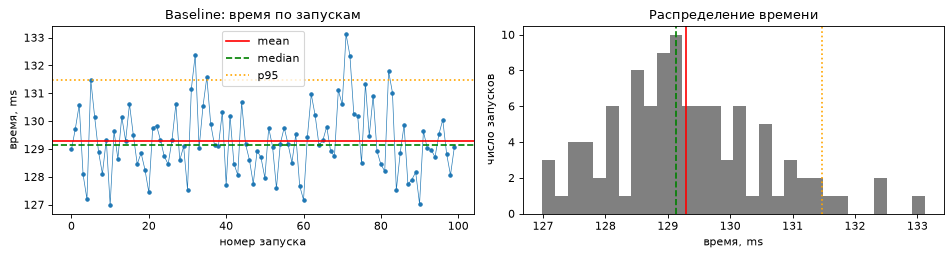

In [7]:
def timing_stats(t):
    n = len(t); mean = t.mean(); s = t.std(ddof=1)
    half = 1.96 * s / np.sqrt(n)
    return dict(n=n, mean=mean, median=np.median(t), std=s, p95=np.percentile(t, 95), ci=(mean - half, mean + half),
                fps=1000.0 / mean, min=t.min(), max=t.max())

def peak_memory_mb(pipeline):
    tracemalloc.start(); pipeline(samples[0]); _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    return peak / 2 ** 20

def mean_quality(pipeline):
    q = np.array([quality(pipeline(x), gt) for x in samples])
    return q[:, 0].mean(), q[:, 0].std(), q[:, 1].mean()

st = timing_stats(steady)
iou_b, iou_b_std, f1_b = mean_quality(baseline)
print(f"baseline, n = {st['n']} после {N_WARMUP} прогревочных запусков")
print(f"  mean   = {st['mean']:.2f} ms      median = {st['median']:.2f} ms      std = {st['std']:.2f} ms")
print(f"  p95    = {st['p95']:.2f} ms      min..max = {st['min']:.2f}..{st['max']:.2f} ms")
print(f"  95% CI среднего = [{st['ci'][0]:.2f}, {st['ci'][1]:.2f}] ms")
print(f"  FPS    = {st['fps']:.2f}")
print(f"  качество: IoU = {iou_b:.4f} ± {iou_b_std:.4f} по {N_SAMPLES} кадрам, F1 = {f1_b:.4f}")
print(f"  пиковая память Python-объектов за один вызов: {peak_memory_mb(baseline):.1f} МБ")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.3))
ax[0].plot(steady, ".-", lw=0.6); ax[0].axhline(st["mean"], color="r", label="mean"); ax[0].axhline(st["median"], color="g", ls="--", label="median"); ax[0].axhline(st["p95"], color="orange", ls=":", label="p95")
ax[0].set(title="Baseline: время по запускам", xlabel="номер запуска", ylabel="время, ms"); ax[0].legend()
ax[1].hist(steady, bins=30, color="gray"); ax[1].axvline(st["mean"], color="r"); ax[1].axvline(st["median"], color="g", ls="--"); ax[1].axvline(st["p95"], color="orange", ls=":")
ax[1].set(title="Распределение времени", xlabel="время, ms", ylabel="число запусков")
plt.tight_layout(); plt.show()

«Пиковая память» измерена `tracemalloc`: он видит массивы NumPy (включая те, что возвращает OpenCV), но не внутренние временные буферы библиотек. Это нижняя оценка, пригодная для сравнения вариантов между собой.

### Шаги 8–9. Оптимизации и повторные измерения в тех же условиях

Основная оптимизация — **уменьшение входа** перед кластеризацией: k-means работает с каждым пикселем, и при уменьшении стороны вдвое пикселей становится вчетверо меньше. Проверяем масштабы от 0.5 до 0.03125 (кадр 20×15). Для сравнения — вариант другого класса: фиксированный порог по яркости, почти бесплатный по времени.

Все варианты измеряются той же функцией `measure`: те же 10 кадров, тот же прогрев, те же 100 замеров, один процесс.

In [8]:
variants = {
    "k-means, scale 1.0 (baseline)": baseline,
    "k-means, scale 0.5": lambda x: pipeline_kmeans(x, 0.5),
    "k-means, scale 0.25": lambda x: pipeline_kmeans(x, 0.25),
    "k-means, scale 0.125": lambda x: pipeline_kmeans(x, 0.125),
    "k-means, scale 0.0625": lambda x: pipeline_kmeans(x, 0.0625),
    "k-means, scale 0.03125": lambda x: pipeline_kmeans(x, 0.03125),
    "threshold 127": pipeline_threshold,
}
table = {}
for name, fn in variants.items():
    t = steady if "baseline" in name else measure(fn)
    table[name] = dict(timing_stats(t), iou=mean_quality(fn)[0], iou_std=mean_quality(fn)[1], f1=mean_quality(fn)[2], mem=peak_memory_mb(fn), times=t)

print(f"{'Вариант':31}{'IoU':>7}{'F1':>7}{'Mean ms':>9}{'Median':>8}{'P95':>8}{'Std':>7}{'95% CI среднего':>20}{'FPS':>9}{'Память, МБ':>12}")
for name, r in table.items():
    ci = "[%.2f, %.2f]" % r["ci"]
    print(f"{name:31}{r['iou']:7.3f}{r['f1']:7.3f}{r['mean']:9.2f}{r['median']:8.2f}{r['p95']:8.2f}{r['std']:7.2f}{ci:>20}{r['fps']:9.1f}{r['mem']:12.1f}")

Вариант                            IoU     F1  Mean ms  Median     P95    Std     95% CI среднего      FPS  Память, МБ
k-means, scale 1.0 (baseline)    0.609  0.757   129.30  129.13  131.47   1.24    [129.06, 129.54]      7.7        10.5
k-means, scale 0.5               0.603  0.753    25.79   25.73   26.37   0.40      [25.71, 25.86]     38.8         2.9
k-means, scale 0.25              0.626  0.770     7.26    7.25    7.72   0.26        [7.20, 7.31]    137.8         0.9
k-means, scale 0.125             0.653  0.790     2.47    2.41    2.74   0.15        [2.44, 2.50]    405.0         0.7
k-means, scale 0.0625            0.706  0.827     1.26    1.22    1.47   0.10        [1.24, 1.28]    796.3         0.6
k-means, scale 0.03125           0.597  0.747     0.92    0.89    1.10   0.09        [0.90, 0.94]   1087.9         0.6
threshold 127                    0.433  0.603     0.09    0.08    0.19   0.03        [0.08, 0.09]  11381.6         0.6


### Шаг 10. Speedup и относительное изменение качества

In [9]:
base = table["k-means, scale 1.0 (baseline)"]
print(f"{'Вариант':31}{'Speedup':>9}{'ΔIoU':>9}{'ΔIoU, %':>9}{'p95/median':>12}{'CI пересекается с baseline?':>30}")
for name, r in table.items():
    overlap = not (r["ci"][1] < base["ci"][0] or r["ci"][0] > base["ci"][1])
    print(f"{name:31}{base['mean'] / r['mean']:9.2f}{r['iou'] - base['iou']:+9.3f}{100 * (r['iou'] - base['iou']) / base['iou']:+9.1f}{r['p95'] / r['median']:12.2f}{('да' if overlap else 'нет'):>30}")
print("\nожидаемое ускорение, если бы всё время зависело от числа пикселей: ×4 (0.5), ×16 (0.25), ×64 (0.125), ×256 (0.0625), ×1024 (0.03125)")

# почему качество меняется с масштабом: FP и FN на первом кадре
print(f"\n{'Вариант':31}{'FP':>8}{'FN':>8}{'Precision':>11}{'Recall':>9}")
for name, fn in variants.items():
    pr = fn(samples[0]); tp = (pr & gt).sum(); fp = (pr & ~gt).sum(); fn_ = (~pr & gt).sum()
    print(f"{name:31}{int(fp):8d}{int(fn_):8d}{tp / (tp + fp + 1e-12):11.3f}{tp / (tp + fn_ + 1e-12):9.3f}")

Вариант                          Speedup     ΔIoU  ΔIoU, %  p95/median   CI пересекается с baseline?
k-means, scale 1.0 (baseline)       1.00   +0.000     +0.0        1.02                            да
k-means, scale 0.5                  5.01   -0.005     -0.9        1.02                           нет
k-means, scale 0.25                17.82   +0.018     +2.9        1.06                           нет
k-means, scale 0.125               52.37   +0.045     +7.4        1.14                           нет
k-means, scale 0.0625             102.96   +0.097    +15.9        1.21                           нет
k-means, scale 0.03125            140.67   -0.011     -1.9        1.24                           нет
threshold 127                    1471.63   -0.176    -28.9        2.37                           нет

ожидаемое ускорение, если бы всё время зависело от числа пикселей: ×4 (0.5), ×16 (0.25), ×64 (0.125), ×256 (0.0625), ×1024 (0.03125)

Вариант                              FP      FN  Precisio

Вторая таблица объясняет неожиданный результат: при уменьшении входа качество не падает, а **растёт** — вплоть до масштаба 0.0625. Уменьшение с усреднением (`INTER_AREA`) работает как сглаживание: мелкие красные цветы узора ткани, которые на полном кадре попадали в кластер «объект» (FP — лабораторная 10), усредняются с окружающим фоном и перестают быть красными. Число FP падает с ≈ 17 тысяч до ≈ 3 тысяч. FN при этом растут медленно — пока объект остаётся намного крупнее пикселя уменьшенного кадра. На масштабе 0.03125 (кадр 20×15) маленький прямоугольник занимает уже около двух пикселей, FN резко растут, и качество падает.

### Шаг 11. Граница Парето

Та же функция `pareto`, что решала вопрос 2, применяется к измеренным парам (IoU, FPS).

Pareto frontier:

 ['k-means, scale 0.0625', 'k-means, scale 0.03125', 'threshold 127']
dominated: {'k-means, scale 1.0 (baseline)': ['k-means, scale 0.25', 'k-means, scale 0.125', 'k-means, scale 0.0625'], 'k-means, scale 0.5': ['k-means, scale 0.25', 'k-means, scale 0.125', 'k-means, scale 0.0625'], 'k-means, scale 0.25': ['k-means, scale 0.125', 'k-means, scale 0.0625'], 'k-means, scale 0.125': ['k-means, scale 0.0625']}


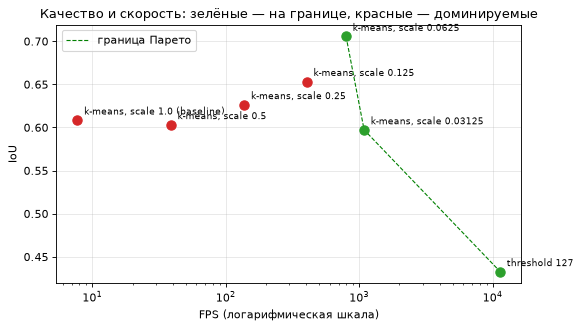

In [10]:
pts = {name: (r["iou"], r["fps"]) for name, r in table.items()}
front, dom = pareto(pts)
print("Pareto frontier:", front)
print("dominated:", dom if dom else "нет")

plt.figure(figsize=(7.5, 4.2))
for name, (q, f) in pts.items():
    on = name in front
    plt.scatter(f, q, s=70, c="tab:green" if on else "tab:red", zorder=3)
    plt.annotate(name, (f, q), fontsize=8, xytext=(6, 5), textcoords="offset points")
fr = sorted([pts[n] for n in front], key=lambda p: p[1])
plt.plot([p[1] for p in fr], [p[0] for p in fr], "g--", lw=1, label="граница Парето")
plt.xscale("log"); plt.xlabel("FPS (логарифмическая шкала)"); plt.ylabel("IoU"); plt.title("Качество и скорость: зелёные — на границе, красные — доминируемые")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 5. Неудачные случаи: как получить неверный вывод из верных замеров

### Мало замеров

Возьмём из 100 замеров baseline случайные подвыборки по 5 и посмотрим, какие «средние» можно было бы получить.

In [11]:
rng = np.random.default_rng(SEED)
t_base = table["k-means, scale 1.0 (baseline)"]["times"]
for n_small in (5, 20):
    means = np.array([rng.choice(t_base, n_small, replace=False).mean() for _ in range(2000)])
    half = 1.96 * t_base.std(ddof=1) / np.sqrt(n_small)
    print(f"n = {n_small:2d}: среднее по подвыборке от {means.min():.2f} до {means.max():.2f} ms; типичная полуширина 95% CI ≈ ±{half:.2f} ms")
print(f"n = 100: 95% CI = [{base['ci'][0]:.2f}, {base['ci'][1]:.2f}] ms, полуширина ±{(base['ci'][1] - base['ci'][0]) / 2:.2f} ms")

# без прогрева: первые 5 вызовов как «измерение»
print(f"\n«измерение» по первым 5 вызовам без прогрева: mean = {np.mean(first[:5]):.2f} ms против {base['mean']:.2f} ms в установившемся режиме ({100 * (np.mean(first[:5]) / base['mean'] - 1):+.0f} %)")

n =  5: среднее по подвыборке от 127.83 до 131.35 ms; типичная полуширина 95% CI ≈ ±1.09 ms
n = 20: среднее по подвыборке от 128.39 до 130.32 ms; типичная полуширина 95% CI ≈ ±0.54 ms
n = 100: 95% CI = [129.06, 129.54] ms, полуширина ±0.24 ms

«измерение» по первым 5 вызовам без прогрева: mean = 146.25 ms против 129.30 ms в установившемся режиме (+13 %)


### Сравнение FPS без оговорки о качестве и условиях

In [12]:
fast = max(table, key=lambda k: table[k]["fps"])
print(f"самый быстрый вариант: «{fast}» — {table[fast]['fps']:.0f} FPS, в {table[fast]['fps'] / base['fps']:.0f} раз быстрее baseline")
print(f"его IoU: {table[fast]['iou']:.3f} против {base['iou']:.3f} у baseline")
print("\nустойчивость качества к условиям съёмки (std IoU по 10 кадрам с разным шумом и освещением):")
for name, r in table.items():
    print(f"  {name:31} IoU = {r['iou']:.3f} ± {r['iou_std']:.3f}")

самый быстрый вариант: «threshold 127» — 11382 FPS, в 1472 раз быстрее baseline
его IoU: 0.433 против 0.609 у baseline

устойчивость качества к условиям съёмки (std IoU по 10 кадрам с разным шумом и освещением):
  k-means, scale 1.0 (baseline)   IoU = 0.609 ± 0.005
  k-means, scale 0.5              IoU = 0.603 ± 0.004
  k-means, scale 0.25             IoU = 0.626 ± 0.006
  k-means, scale 0.125            IoU = 0.653 ± 0.009
  k-means, scale 0.0625           IoU = 0.706 ± 0.004
  k-means, scale 0.03125          IoU = 0.597 ± 0.041
  threshold 127                   IoU = 0.433 ± 0.046


Три способа ошибиться, не солгав ни в одном числе.

1. **Мало замеров.** По пяти запускам «среднее» baseline могло бы получиться любым от 127.8 до 131.4 ms при настоящем 129.3 ms. Здесь разброс мал и на выводы не влияет; но если бы два варианта различались на 2 %, по пяти замерам их нельзя было бы различить. Два варианта, чьи доверительные интервалы пересекаются, считаются неразличимыми.
2. **Нет прогрева.** Первый вызов занял 215 ms при установившихся 129 ms; «измерение» по первым пяти вызовам завысило бы время на 13 %.
3. **Только FPS.** Пороговый вариант даёт больше 11 тысяч FPS — в 1472 раза быстрее baseline — и выглядит победителем, пока не посмотреть на качество: IoU 0.433 против 0.609, и разброс между кадрами в десять раз больше. И наоборот: сравнивать FPS вариантов, измеренных на разных машинах, с разным размером входа или разным числом потоков, бессмысленно — в этом ноутбуке все варианты получают один и тот же кадр 640×480, а уменьшение входа считается частью конвейера и входит в измеряемое время.

## 6. Вывод

Времена относятся к машине, на которой выполнен ноутбук; итоговая таблица — в ячейке шагов 8–9.

- **Ручные расчёты:** mean = 26 ms, median = 20 ms; 95 % CI = [24.02, 25.98] ms; D доминируется C, граница — A, B, C, E. Функция `pareto` даёт тот же ответ.
- **Baseline:** 129.3 ms на кадр (7.7 FPS), IoU 0.609. Среднее и медиана почти совпали (129.30 и 129.13 ms), p95 = 131.5 ms, std 1.2 ms: распределение узкое и почти симметричное, выбросов нет. 95 % CI среднего — [129.06, 129.54] ms.
- **Среднее, медиана и p95 нужны вместе** — это видно на быстрых вариантах. Чем короче запуск, тем больше в нём доля случайных задержек системы: отношение p95/median растёт от 1.02 у baseline до 1.21–1.24 у самых мелких масштабов и 2.4 у порогового варианта (median 0.08 ms, p95 0.19 ms). Для него среднее уже плохо описывает типичный запуск.
- **Итоговая таблица:**

| Вариант | Quality (IoU) | Mean ms | Median / P95 ms | FPS | Speedup |
|---|---|---|---|---|---|
| k-means, scale 1.0 (baseline) | 0.609 | 129.30 | 129.13 / 131.47 | 7.7 | 1.0 |
| k-means, scale 0.5 | 0.603 | 25.79 | 25.73 / 26.37 | 38.8 | 5.0 |
| k-means, scale 0.25 | 0.626 | 7.26 | 7.25 / 7.72 | 137.8 | 17.8 |
| k-means, scale 0.125 | 0.653 | 2.47 | 2.41 / 2.74 | 405 | 52.4 |
| k-means, scale 0.0625 | 0.706 | 1.26 | 1.22 / 1.47 | 796 | 103 |
| k-means, scale 0.03125 | 0.597 | 0.92 | 0.89 / 1.10 | 1088 | 141 |
| threshold 127 | 0.433 | 0.09 | 0.08 / 0.19 | 11 382 | 1472 |

- **Оптимизация улучшила и скорость, и качество.** Ожидалась плата качеством за скорость; получилось иначе: при масштабе 0.0625 конвейер в 103 раза быстрее baseline и точнее на 0.097 IoU (+16 %). Причина — в самой задаче: усреднение при уменьшении убирает мелкий узор ткани, дававший ложные срабатывания. Это свойство данной сцены, а не общий закон: если бы объект был мелким или имел тонкие детали, уменьшение их уничтожило бы. Предел виден и здесь: при масштабе 0.03125 IoU падает до 0.597, а разброс между кадрами вырастает с ±0.004 до ±0.041 — результат становится неустойчивым.
- **Ускорение и число пикселей.** До масштаба 0.25 ускорение даже немного выше, чем уменьшение числа пикселей (×5.0 и ×17.8 при ожидаемых ×4 и ×16): меньший массив лучше помещается в кэш процессора. Дальше оно отстаёт всё сильнее: ×52 вместо ×64, ×103 вместо ×256, ×141 вместо ×1024. Перевод цветового пространства, уменьшение кадра 640×480 и возврат маски к полному размеру от масштаба почти не зависят; чем быстрее становится k-means, тем большую долю времени занимают эти постоянные расходы (закон Амдала).
- **Парето.** На границе три варианта: scale 0.0625 (лучшее качество), scale 0.03125 и threshold 127 (максимум скорости). Baseline и масштабы 0.5, 0.25, 0.125 **доминируются**: вариант 0.0625 одновременно и точнее, и быстрее каждого из них. Доверительные интервалы времени у вариантов не пересекаются, различия в скорости достоверны.
- **Когда оптимизация оправдана.** Здесь — безусловно: baseline с 7.7 FPS не годится для реального времени и при этом проигрывает в качестве. Разумный выбор — масштаб 0.0625 или, с запасом от обрыва качества, 0.125 (IoU 0.653, 405 FPS). Масштаб 0.03125 быстрее всего на 37 %, а IoU теряет 0.11 и становится нестабильным — плата слишком велика. Пороговый вариант быстрее ещё в 10 раз, но IoU 0.433 с разбросом ±0.046: приемлем только там, где скорость важнее всего остального.
- **Память:** пик Python-объектов падает с 10.5 МБ у baseline до 0.6–0.9 МБ у уменьшенных вариантов.
- **Ограничения:** одна сцена в десяти вариантах шума и освещения, один компьютер, CPU; качество измерено на составном изображении (см. лабораторную 10). Вывод «уменьшение повышает качество» нельзя переносить на другие сцены без проверки.

## 7. Вопросы на защиту

**1. Почему median и p95 нужны вместе со средним временем?**
Распределение времени несимметрично: быстрее минимума запуск быть не может, а медленнее — сколько угодно. Среднее смешивает типичное поведение и редкие выбросы в одно число; по нему не видно, было ли 100 запусков по 26 ms или 99 по 20 и один в 620. Медиана показывает типичный случай, p95 — хвост. Для систем реального времени важен именно хвост: кадр, опоздавший к дедлайну, потерян, даже если в среднем всё хорошо.

**2. Что означает Pareto-dominated решение и почему максимум FPS сам по себе не определяет лучший pipeline?**
Решение доминируется, если есть другое, которое не хуже по всем критериям и лучше хотя бы по одному; выбирать доминируемое незачем при любых приоритетах. Максимальный FPS — крайняя точка границы: обычно это вариант с наихудшим качеством. «Лучший» зависит от требований: минимально допустимое качество, требуемая частота кадров, бюджет памяти. Граница Парето отсекает заведомо плохие варианты, а выбор среди оставшихся делает инженер.

**3. Участок timing-кода; warm-up, синхронизация GPU, одинаковые условия.**
В `measure`: первый цикл — `warmup` запусков без записи времени (кэши, выделение памяти, ленивая инициализация библиотек). Второй — замеры: `time.perf_counter()` (монотонные часы высокого разрешения) до и после вызова, и только вызова конвейера: подготовка данных в замер не входит. На GPU операции ставятся в очередь и выполняются асинхронно, поэтому без `torch.cuda.synchronize()` перед стартом и перед остановкой таймера измерилось бы время постановки в очередь, а не вычисления. Одинаковые условия: все варианты получают одни и те же 10 кадров в том же порядке, одно и то же число запусков, выполняются в одном процессе на одной машине; число итераций k-means фиксировано, чтобы объём работы не зависел от данных.